# RCAEval Dataset Exploration

Goal: understand the RCAEval dataset structure, distinguish telemetry from ground truth,
and build a very simple baseline before trying more complex AI methods.

Imports and metadata

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from huggingface_hub import list_repo_files, hf_hub_download

cases = pd.read_parquet(
    "hf://datasets/phamquiluan/RCAEval/cases.parquet"
)

print("Shape:", cases.shape)
print("Columns:", cases.columns.tolist())

cases.head()

Shape: (735, 22)
Columns: ['case', 'dataset', 'suite', 'system', 'system_name', 'root_cause_service', 'fault', 'fault_description', 'repetition', 'inject_time', 'n_metrics', 'n_timesteps', 'time_start', 'time_end', 'duration_minutes', 'normal_timesteps', 'faulty_timesteps', 'has_logs', 'n_logs', 'has_traces', 'n_traces', 'has_root_cause_file']


,case,dataset,suite,system,system_name,root_cause_service,fault,fault_description,repetition,inject_time,...,time_start,time_end,duration_minutes,normal_timesteps,faulty_timesteps,has_logs,n_logs,has_traces,n_traces,has_root_cause_file
0,re1ob_adservice_cpu_1,RE1-OB,RE1,ob,Online Boutique,adservice,cpu,CPU stress,1,1685202688,...,1685200588,1685204788,70.0,2100,2101,False,0,False,0,False
1,re1ob_adservice_cpu_2,RE1-OB,RE1,ob,Online Boutique,adservice,cpu,CPU stress,2,1685206967,...,1685204867,1685209067,70.0,2100,2101,False,0,False,0,False
2,re1ob_adservice_cpu_3,RE1-OB,RE1,ob,Online Boutique,adservice,cpu,CPU stress,3,1685211245,...,1685209145,1685213345,70.0,2100,2101,False,0,False,0,False
3,re1ob_adservice_cpu_4,RE1-OB,RE1,ob,Online Boutique,adservice,cpu,CPU stress,4,1685229704,...,1685227604,1685231804,70.0,2100,2101,False,0,False,0,False
4,re1ob_adservice_cpu_5,RE1-OB,RE1,ob,Online Boutique,adservice,cpu,CPU stress,5,1685220134,...,1685218034,1685222234,70.0,2100,2101,False,0,False,0,False


Inspect one incident

In [ ]:
case = cases.iloc[0]

print("Case:", case["case"])
print("System:", case["system_name"])
print("Root cause service:", case["root_cause_service"])
print("Fault:", case["fault"])
print("Description:", case["fault_description"])

Case: re1ob_adservice_cpu_1
System: Online Boutique
Root cause service: adservice
Fault: cpu
Description: CPU stress


## Ground Truth vs Input Evidence

Fields such as:

- `root_cause_service`
- `fault`
- `fault_description`

are part of the benchmark answer / ground truth.

They must not be exposed to the RCA method during inference.

The RCA method should instead use telemetry such as:

- metrics
- logs
- traces

and predict the root cause.

The evaluator then compares the prediction with the hidden ground truth.

Find files belonging to the incident

In [ ]:
files = list_repo_files(
    "phamquiluan/RCAEval",
    repo_type="dataset"
)

case_name = case["case"]

case_files = [
    file
    for file in files
    if case_name in file
]

case_files

['re1ob_adservice_cpu_1/inject_time.txt',
 're1ob_adservice_cpu_1/metrics.parquet']

Load injection time

In [ ]:
inject_path = hf_hub_download(
    repo_id="phamquiluan/RCAEval",
    filename=f"{case_name}/inject_time.txt",
    repo_type="dataset"
)

with open(inject_path, "r") as f:
    inject_time = int(f.read())

print("Injection time:", inject_time)

inject_time.txt:   0%|          | 0.00/10.0 [00:00<?, ?B/s]

Injection time: 1685202688


Load metrics

In [ ]:
metrics = pd.read_parquet(
    f"hf://datasets/phamquiluan/RCAEval/{case_name}/metrics.parquet"
)

print("Shape:", metrics.shape)
print("Columns:", metrics.columns.tolist())

metrics.head()

Shape: (4201, 50)
Columns: ['time', 'adservice_cpu', 'cartservice_cpu', 'checkoutservice_cpu', 'currencyservice_cpu', 'emailservice_cpu', 'frontend_cpu', 'main_cpu', 'paymentservice_cpu', 'productcatalogservice_cpu', 'recommendationservice_cpu', 'redis_cpu', 'shippingservice_cpu', 'adservice_mem', 'cartservice_mem', 'checkoutservice_mem', 'currencyservice_mem', 'emailservice_mem', 'frontend_mem', 'main_mem', 'paymentservice_mem', 'productcatalogservice_mem', 'recommendationservice_mem', 'redis_mem', 'shippingservice_mem', 'PassthroughCluster_load', 'adservice_load', 'cartservice_load', 'checkoutservice_load', 'currencyservice_load', 'emailservice_load', 'frontend_load', 'frontend-external_load', 'paymentservice_load', 'productcatalogservice_load', 'recommendationservice_load', 'shippingservice_load', 'adservice_latency', 'cartservice_latency', 'checkoutservice_latency', 'currencyservice_latency', 'emailservice_latency', 'frontend_latency', 'paymentservice_latency', 'productcatalogservi

,time,adservice_cpu,cartservice_cpu,checkoutservice_cpu,currencyservice_cpu,emailservice_cpu,frontend_cpu,main_cpu,paymentservice_cpu,productcatalogservice_cpu,...,currencyservice_latency,emailservice_latency,frontend_latency,paymentservice_latency,productcatalogservice_latency,recommendationservice_latency,shippingservice_latency,PassthroughCluster_error,frontend_error,frontend-external_error
0,1685200588,44.503283,4.965416,1.947450,7.952500,0.992255,17.725886,7.911334,0.457972,11.843233,...,0.004957,0.0046,0.381486,0.004631,0.006510,0.014185,0.004676,0.0,0.0,0.0
1,1685200589,37.376351,4.957174,1.947450,7.952500,0.992255,17.707375,7.911334,0.408782,11.903299,...,0.004958,0.0046,0.399897,0.004633,0.006516,0.014185,0.004678,0.0,0.0,0.0
2,1685200590,37.376351,4.957174,1.681948,7.836973,0.992255,17.657918,7.911334,0.408782,11.903299,...,0.004958,0.0046,0.399897,0.004631,0.006513,0.014185,0.004677,0.0,0.0,0.0
3,1685200591,37.376351,4.957174,1.649491,7.836973,0.992255,17.657918,7.911334,0.458569,11.903299,...,0.004989,0.0046,0.399897,0.004631,0.006742,0.015335,0.004668,0.0,0.0,0.0
4,1685200592,37.376351,4.957174,1.617033,7.836973,0.992255,17.657918,7.911334,0.458569,11.903299,...,0.005240,0.0046,0.399897,0.004631,0.007011,0.017648,0.004665,0.0,0.0,0.0


Split before and after fault injection

In [ ]:
before = metrics[metrics["time"] < inject_time]
after = metrics[metrics["time"] >= inject_time]

print("Before:", before.shape)
print("After:", after.shape)

Before: (2100, 50)
After: (2101, 50)


Inspect adservice_cpu

In [ ]:
print("Before mean:", before["adservice_cpu"].mean())
print("After mean:", after["adservice_cpu"].mean())

print("Before max:", before["adservice_cpu"].max())
print("After max:", after["adservice_cpu"].max())

Before mean: 1.8272481942894747
After mean: 96.65278309560412
Before max: 44.5032832308396
After max: 100.02011419779615


## Initial Observation

For `re1ob_adservice_cpu_1`, the CPU behavior changes very strongly after
fault injection.

Before injection:
- Average CPU ≈ 1.83

After injection:
- Average CPU ≈ 96.65

This suggests a strong and sustained anomaly in `adservice_cpu`.

Plot the CPU behavior

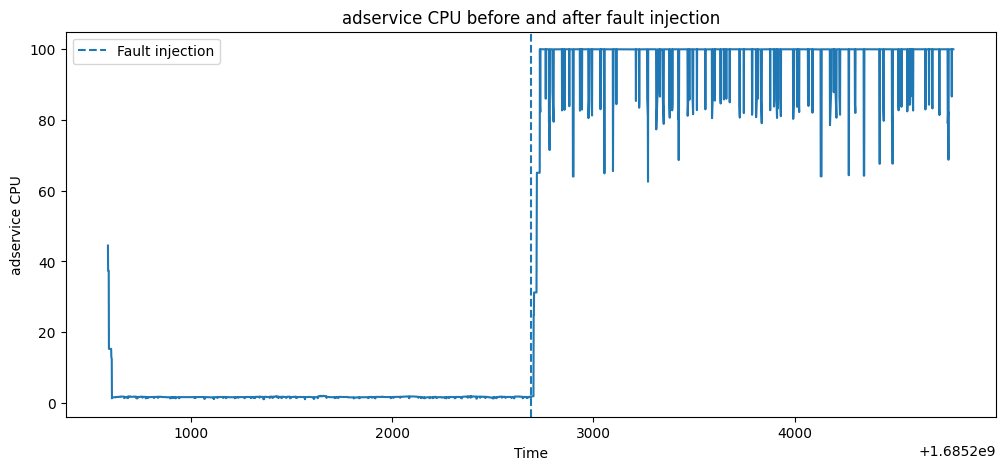

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(metrics["time"], metrics["adservice_cpu"])
plt.axvline(
    inject_time,
    linestyle="--",
    label="Fault injection"
)

plt.xlabel("Time")
plt.ylabel("adservice CPU")
plt.title("adservice CPU before and after fault injection")
plt.legend()

plt.show()

## First Simple Heuristic - Why raw differences are problematic ?

A first idea was to compare:

`|after_mean - before_mean|`

for every metric.

However, this is biased by metric scale.

For example:

- memory can be tens of millions of bytes
- CPU may be around 0–100
- latency may be around 0.001–1

Therefore a small memory change can numerically dominate a large CPU anomaly.

Relative-change heuristic

In [ ]:
def get_top_changed_metric(metrics, inject_time):
    before = metrics[metrics["time"] < inject_time]
    after = metrics[metrics["time"] >= inject_time]

    changes = []

    for col in metrics.columns:
        if col == "time":
            continue

        before_mean = before[col].mean()
        after_mean = after[col].mean()

        relative_change = (
            abs(after_mean - before_mean)
            / (abs(before_mean) + 1e-9)
        )

        changes.append({
            "metric": col,
            "before": before_mean,
            "after": after_mean,
            "relative_change": relative_change
        })

    changes_df = pd.DataFrame(changes)

    return changes_df.sort_values(
        "relative_change",
        ascending=False
    )

ranking = get_top_changed_metric(metrics, inject_time)

ranking.head(10)

,metric,before,after,relative_change
0,adservice_cpu,1.827248e+00,9.665278e+01,51.895268
48,frontend-external_error,3.144524e-02,4.759638e-03,0.848637
37,cartservice_latency,9.360956e-03,6.897447e-03,0.263168
12,adservice_mem,9.439301e+07,1.003284e+08,0.062880
41,frontend_latency,2.489386e-01,2.341065e-01,0.059581
43,productcatalogservice_latency,5.139810e-03,4.928960e-03,0.041023
1,cartservice_cpu,6.108271e+00,5.905601e+00,0.033180
18,main_mem,7.035670e+07,7.237665e+07,0.028710
29,emailservice_load,3.638830e+00,3.711160e+00,0.019878
7,paymentservice_cpu,4.375684e-01,4.289484e-01,0.019700


# Important lesson

Relative change solves the different-scale problem better than raw absolute
difference, but it introduces another problem:

If the baseline is close to zero, even a tiny increase can produce an
extremely large relative-change score.

Select cases from different services

In [ ]:
sample_cases = (
    cases[
        cases["case"].apply(
            lambda x: f"{x}/metrics.parquet" in files
        )
    ]
    .drop_duplicates(
        subset=["root_cause_service"]
    )
    .head(5)
)

sample_cases[
    ["case", "root_cause_service", "fault"]
]

,case,root_cause_service,fault
0,re1ob_adservice_cpu_1,adservice,cpu
25,re1ob_cartservice_cpu_1,cartservice,cpu
50,re1ob_checkoutservice_cpu_1,checkoutservice,cpu
75,re1ob_currencyservice_cpu_1,currencyservice,cpu
100,re1ob_productcatalogservice_cpu_1,productcatalogservice,cpu


Run the tiny baseline

In [ ]:
results = []

for _, row in sample_cases.iterrows():
    case_name = row["case"]

    metrics = pd.read_parquet(
        f"hf://datasets/phamquiluan/RCAEval/{case_name}/metrics.parquet"
    )

    inject_path = hf_hub_download(
        repo_id="phamquiluan/RCAEval",
        filename=f"{case_name}/inject_time.txt",
        repo_type="dataset"
    )

    with open(inject_path, "r") as f:
        inject_time = int(f.read())

    ranking = get_top_changed_metric(metrics, inject_time)

    top_metric = ranking.iloc[0]["metric"]

    predicted_service = top_metric.rsplit("_", 1)[0]

    results.append({
        "case": case_name,
        "ground_truth": row["root_cause_service"],
        "top_metric": top_metric,
        "predicted_service": predicted_service,
        "correct": predicted_service == row["root_cause_service"]
    })

results_df = pd.DataFrame(results)

results_df

inject_time.txt:   0%|          | 0.00/10.0 [00:00<?, ?B/s]

inject_time.txt:   0%|          | 0.00/10.0 [00:00<?, ?B/s]

inject_time.txt:   0%|          | 0.00/10.0 [00:00<?, ?B/s]

inject_time.txt:   0%|          | 0.00/10.0 [00:00<?, ?B/s]

,case,ground_truth,top_metric,predicted_service,correct
0,re1ob_adservice_cpu_1,adservice,adservice_cpu,adservice,True
1,re1ob_cartservice_cpu_1,cartservice,cartservice_cpu,cartservice,True
2,re1ob_checkoutservice_cpu_1,checkoutservice,checkoutservice_cpu,checkoutservice,True
3,re1ob_currencyservice_cpu_1,currencyservice,frontend_error,frontend,False
4,re1ob_productcatalogservice_cpu_1,productcatalogservice,frontend-external_error,frontend-external,False


## Tiny Baseline Result

The simple relative-change heuristic correctly identified the root-cause
service in 3 out of 5 CPU-fault cases.

Correct:
- adservice
- cartservice
- checkoutservice

Incorrect:
- currencyservice → predicted `frontend`
- productcatalogservice → predicted `frontend-external`

This is not yet a formal benchmark result because the sample is very small,
but it already exposes weaknesses in the heuristic.

Inspect one failed case

In [ ]:
failed_case = "re1ob_currencyservice_cpu_1"

metrics = pd.read_parquet(
    f"hf://datasets/phamquiluan/RCAEval/{failed_case}/metrics.parquet"
)

inject_path = hf_hub_download(
    repo_id="phamquiluan/RCAEval",
    filename=f"{failed_case}/inject_time.txt",
    repo_type="dataset"
)

with open(inject_path, "r") as f:
    inject_time = int(f.read())

ranking = get_top_changed_metric(metrics, inject_time)

ranking.head(10)

,metric,before,after,relative_change
47,frontend_error,0.000000,0.001941,1.941456e+06
43,productcatalogservice_latency,0.004886,0.128295,2.525525e+01
44,recommendationservice_latency,0.010323,0.166740,1.515241e+01
39,currencyservice_latency,0.007220,0.085281,1.081143e+01
36,adservice_latency,0.004754,0.054279,1.041841e+01
3,currencyservice_cpu,9.006707,96.791823,9.746638e+00
41,frontend_latency,0.271693,2.845621,9.473665e+00
37,cartservice_latency,0.012798,0.114970,7.983338e+00
45,shippingservice_latency,0.004792,0.034114,6.118547e+00
38,checkoutservice_latency,0.053260,0.284344,4.338803e+00


## Failure Analysis - Why the heuristic failed ?

`frontend_error` received an enormous relative-change score because its
baseline was zero.

The increase itself was tiny, but dividing by an almost-zero baseline caused
the relative score to explode.

Meanwhile, `currencyservice_cpu` changed from approximately 9 to 97, which is
operationally much more significant.

This demonstrates that relative change alone is not a reliable anomaly score.

Plot actual root-cause metric

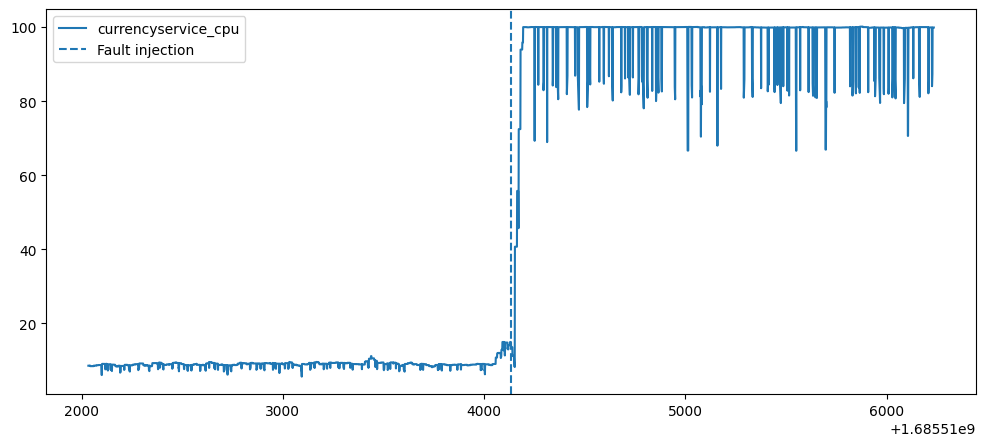

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    metrics["time"],
    metrics["currencyservice_cpu"],
    label="currencyservice_cpu"
)

plt.axvline(
    inject_time,
    linestyle="--",
    label="Fault injection"
)

plt.legend()
plt.show()

Plot misleading downstream symptom

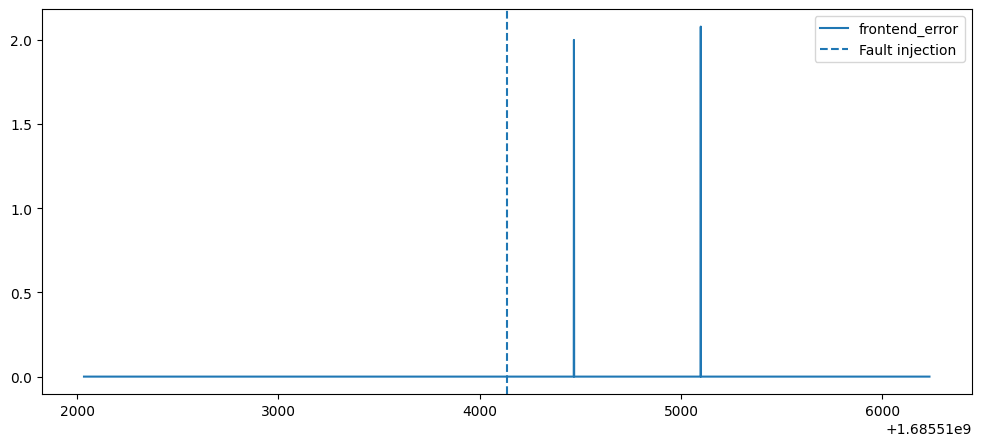

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    metrics["time"],
    metrics["frontend_error"],
    label="frontend_error"
)

plt.axvline(
    inject_time,
    linestyle="--",
    label="Fault injection"
)

plt.legend()
plt.show()

# Explore a Richer Telemetry Case

So far, we only explored RCA cases containing metrics.

The next goal is to find an incident that contains multiple telemetry sources:

- metrics
- logs
- traces

This will let us understand what information an RCA system can actually use beyond simple metric anomalies.

We will first find which benchmark cases contain all three telemetry types.

In [ ]:
# Find case names that contain each telemetry type

metric_case_names = {
    path.split("/", 1)[0]
    for path in files
    if path.endswith("/metrics.parquet")
}

log_case_names = {
    path.split("/", 1)[0]
    for path in files
    if path.endswith("/logs.parquet")
}

trace_case_names = {
    path.split("/", 1)[0]
    for path in files
    if path.endswith("/traces.parquet")
}

print("Cases with metrics:", len(metric_case_names))
print("Cases with logs:", len(log_case_names))
print("Cases with traces:", len(trace_case_names))


# Cases containing all three telemetry types

rich_case_names = (
    metric_case_names
    & log_case_names
    & trace_case_names
)

print("Cases with metrics + logs + traces:", len(rich_case_names))


# Show some of those cases together with their ground truth metadata

rich_cases = cases[
    cases["case"].isin(rich_case_names)
][
    [
        "case",
        "dataset",
        "system_name",
        "root_cause_service",
        "fault"
    ]
]

rich_cases.head(10)

Cases with metrics: 735
Cases with logs: 359
Cases with traces: 240
Cases with metrics + logs + traces: 239


,case,dataset,system_name,root_cause_service,fault
375,re2ob_checkoutservice_cpu_1,RE2-OB,Online Boutique,checkoutservice,cpu
376,re2ob_checkoutservice_cpu_2,RE2-OB,Online Boutique,checkoutservice,cpu
377,re2ob_checkoutservice_cpu_3,RE2-OB,Online Boutique,checkoutservice,cpu
378,re2ob_checkoutservice_delay_1,RE2-OB,Online Boutique,checkoutservice,delay
379,re2ob_checkoutservice_delay_2,RE2-OB,Online Boutique,checkoutservice,delay
380,re2ob_checkoutservice_delay_3,RE2-OB,Online Boutique,checkoutservice,delay
381,re2ob_checkoutservice_disk_1,RE2-OB,Online Boutique,checkoutservice,disk
382,re2ob_checkoutservice_disk_2,RE2-OB,Online Boutique,checkoutservice,disk
383,re2ob_checkoutservice_disk_3,RE2-OB,Online Boutique,checkoutservice,disk
384,re2ob_checkoutservice_loss_1,RE2-OB,Online Boutique,checkoutservice,loss


# Inspect One Multi-Telemetry Incident

We now know that RCAEval contains many cases with:

- metrics
- logs
- traces

We will inspect one incident first:

`re2ob_checkoutservice_cpu_1`

The goal is not to diagnose it yet.

The goal is to understand:

1. what the log table looks like,
2. what the trace table looks like,
3. what one row represents in each telemetry source,
4. how these sources differ from metrics.

In [ ]:
rich_case_name = "re2ob_checkoutservice_cpu_1"

rich_case = cases[
    cases["case"] == rich_case_name
].iloc[0]

print("Case:", rich_case["case"])
print("System:", rich_case["system_name"])
print("Root cause service:", rich_case["root_cause_service"])
print("Fault:", rich_case["fault"])

Case: re2ob_checkoutservice_cpu_1
System: Online Boutique
Root cause service: checkoutservice
Fault: cpu


The fields above are still ground truth.

We inspect them during dataset exploration so we understand the case, but later an RCA method must not use them as input.

In [ ]:
rich_case_files = [
    path
    for path in files
    if rich_case_name in path
]

rich_case_files

rich_metrics = pd.read_parquet(
    f"hf://datasets/phamquiluan/RCAEval/{rich_case_name}/metrics.parquet"
)

rich_logs = pd.read_parquet(
    f"hf://datasets/phamquiluan/RCAEval/{rich_case_name}/logs.parquet"
)

rich_traces = pd.read_parquet(
    f"hf://datasets/phamquiluan/RCAEval/{rich_case_name}/traces.parquet"
)

print("Metrics shape:", rich_metrics.shape)
print("Logs shape:", rich_logs.shape)
print("Traces shape:", rich_traces.shape)

print("METRICS COLUMNS")
print(rich_metrics.columns.tolist())

print("\nLOG COLUMNS")
print(rich_logs.columns.tolist())

print("\nTRACE COLUMNS")
print(rich_traces.columns.tolist())

Metrics shape: (1441, 73)
Logs shape: (171322, 3)
Traces shape: (391997, 11)
METRICS COLUMNS
['time', 'adservice_cpu', 'cartservice_cpu', 'checkoutservice_cpu', 'currencyservice_cpu', 'emailservice_cpu', 'frontend_cpu', 'paymentservice_cpu', 'productcatalogservice_cpu', 'recommendationservice_cpu', 'redis_cpu', 'shippingservice_cpu', 'adservice_mem', 'cartservice_mem', 'checkoutservice_mem', 'currencyservice_mem', 'emailservice_mem', 'frontend_mem', 'paymentservice_mem', 'productcatalogservice_mem', 'recommendationservice_mem', 'redis_mem', 'shippingservice_mem', 'adservice_diskio', 'emailservice_diskio', 'recommendationservice_diskio', 'redis_diskio', 'adservice_socket', 'cartservice_socket', 'checkoutservice_socket', 'currencyservice_socket', 'emailservice_socket', 'frontend_socket', 'paymentservice_socket', 'productcatalogservice_socket', 'recommendationservice_socket', 'redis_socket', 'shippingservice_socket', 'adservice_workload', 'cartservice_workload', 'checkoutservice_workload'

At this point, do not try to interpret every field.

We only want to answer:

### Metrics

Metrics are numerical time-series signals.

Example idea:

`checkoutservice_cpu = 95`

They tell us:

> "How is the system behaving numerically?"

---

### Logs

Logs are event/message records emitted by applications or infrastructure.

Example idea:

`checkoutservice: failed to connect to paymentservice`

They can tell us:

> "What happened?"

---

### Traces

Traces describe how one request flows through multiple services.

Conceptually:

`frontend -> checkoutservice -> paymentservice -> database`

They can tell us:

> "Where did a request travel, how long did each step take, and where might it have failed?"

---

Together:

metrics -> something is abnormal  
logs -> what event/error happened  
traces -> how the failure propagated through services

## Understanding the Log and Trace Schemas

### Logs

The log table has three columns:

- `timestamp`
- `container_name`
- `message`

One row represents **one log event emitted by one service at one point in time**.

For example:

`currencyservice | conversion request successful`

means that `currencyservice` emitted a log message saying that a conversion request completed successfully.

So the basic structure is:

`time -> service -> event/message`

Unlike metrics, logs are mainly discrete events rather than continuous numeric signals.

In [ ]:
print("Log columns:", rich_logs.columns.tolist())
print("Number of log records:", len(rich_logs))

rich_logs.head(10)

Log columns: ['timestamp', 'container_name', 'message']
Number of log records: 171322


,timestamp,container_name,message
0,1705353846,currencyservice,conversion request successful
1,1705353846,currencyservice,conversion request successful
2,1705353846,frontend,request started
3,1705353846,frontend,serving product page
4,1705353846,currencyservice,conversion request successful
5,1705353846,frontend,request started
6,1705353846,frontend,serving product page
7,1705353846,currencyservice,Getting supported currencies...
8,1705353846,currencyservice,Getting supported currencies...
9,1705353846,currencyservice,conversion request successful


### Traces

The trace table is different.

Importantly, **one row is not one complete trace**.

One row represents a **span**.

A trace represents an entire request flowing through the distributed system, while
a span represents one operation performed as part of that request.

The important fields are:

- `traceID`: identifies all spans belonging to the same request
- `spanID`: identifies this individual span
- `parentSpanID`: identifies the span that called/created this span
- `serviceName`: service executing this operation
- `methodName`: method or RPC operation
- `operationName`: more detailed operation description
- `startTimeMillis`: when the span started
- `duration`: how long the span took
- `statusCode`: result/status associated with the span

In [ ]:
example_trace_id = rich_traces.iloc[0]["traceID"]

example_trace = rich_traces[
    rich_traces["traceID"] == example_trace_id
]

example_trace[
    [
        "traceID",
        "spanID",
        "parentSpanID",
        "serviceName",
        "methodName",
        "operationName",
        "duration",
        "statusCode"
    ]
]

,traceID,spanID,parentSpanID,serviceName,methodName,operationName,duration,statusCode
0,46d5d1e1fc25a09db4a81d4d105cee3d,de79080386c4c5c3,433c41ba31b519dd,currencyservice,Convert,grpc.hipstershop.CurrencyService/Convert,186,0
1,46d5d1e1fc25a09db4a81d4d105cee3d,433c41ba31b519dd,6de46372468bc931,frontendservice,Convert,hipstershop.CurrencyService/Convert,4133,0
2,46d5d1e1fc25a09db4a81d4d105cee3d,28de2c1a557175ec,6de46372468bc931,frontendservice,Convert,hipstershop.CurrencyService/Convert,3587,0
3,46d5d1e1fc25a09db4a81d4d105cee3d,a6ccc9fc0e441e5c,28de2c1a557175ec,currencyservice,Convert,grpc.hipstershop.CurrencyService/Convert,134,0
5,46d5d1e1fc25a09db4a81d4d105cee3d,6c8bf0776c7f9ad6,6de46372468bc931,frontendservice,Convert,hipstershop.CurrencyService/Convert,94095,0
6,46d5d1e1fc25a09db4a81d4d105cee3d,4d16d3cbea822f53,6c8bf0776c7f9ad6,currencyservice,Convert,grpc.hipstershop.CurrencyService/Convert,98,0
16,46d5d1e1fc25a09db4a81d4d105cee3d,3cd1e78fc8f3c221,6de46372468bc931,frontendservice,Convert,hipstershop.CurrencyService/Convert,3868,0
19,46d5d1e1fc25a09db4a81d4d105cee3d,5b5e0d3f6f2f1ea3,3cd1e78fc8f3c221,currencyservice,Convert,grpc.hipstershop.CurrencyService/Convert,101,0
20,46d5d1e1fc25a09db4a81d4d105cee3d,290ac0c2cbad7235,6de46372468bc931,frontendservice,Convert,hipstershop.CurrencyService/Convert,92602,0
23,46d5d1e1fc25a09db4a81d4d105cee3d,7392908f7f17b6c7,290ac0c2cbad7235,currencyservice,Convert,grpc.hipstershop.CurrencyService/Convert,97,0


In [ ]:
print("Number of spans:", len(rich_traces))
print("Number of unique traces:", rich_traces["traceID"].nunique())

print(
    "Average spans per trace:",
    len(rich_traces) / rich_traces["traceID"].nunique()
)

Number of spans: 391997
Number of unique traces: 23969
Average spans per trace: 16.354332679711295


In [ ]:
print("Number of log events:", len(rich_logs))

print("\nLog events per service:")
print(
    rich_logs["container_name"]
    .value_counts()
)

Number of log events: 171322

Log events per service:
container_name
frontend                 61202
currencyservice          54754
cartservice              17778
recommendationservice    12929
adservice                10373
shippingservice          10252
checkoutservice           2007
paymentservice            1338
emailservice               669
redis                       20
Name: count, dtype: Int64


## Current Telemetry Model

We can now think of the three telemetry sources as:

### Metrics

Continuous numeric measurements over time.

Example:

`checkoutservice_cpu = 95`

Useful for detecting:
- resource saturation
- latency increases
- memory changes
- error-rate changes

---

### Logs

Discrete events/messages produced by services.

Example:

`currencyservice -> conversion request successful`

Useful for finding:
- errors
- warnings
- exceptions
- unusual application events
- operation outcomes

---

### Traces

Distributed request execution represented as multiple spans.

Example:

`frontendservice -> currencyservice`

Useful for understanding:
- service dependencies
- request propagation
- slow operations
- failed operations
- which downstream service caused an upstream request to degrade

The three telemetry types provide different kinds of evidence rather than being interchangeable.

# Logs Before vs After Fault Injection

Now that we understand the log schema, we want to see whether log behavior changes after the fault is injected.

We will use the same idea as with metrics:

before injection vs after injection

## What are we checking?

We are not diagnosing the incident yet.

We are asking a simpler question:

> Does the distribution of log activity change after fault injection?

For example, a service might suddenly:

- produce many more logs,
- produce fewer logs,
- start emitting new error messages.

A change in log volume alone is not proof of root cause, but it can provide useful evidence.

In [ ]:
# Load the injection time for this richer incident

inject_path = hf_hub_download(
    repo_id="phamquiluan/RCAEval",
    filename=f"{rich_case_name}/inject_time.txt",
    repo_type="dataset"
)

with open(inject_path, "r") as f:
    rich_inject_time = int(f.read())

print("Injection time:", rich_inject_time)

logs_before = rich_logs[
    rich_logs["timestamp"] < rich_inject_time
]

logs_after = rich_logs[
    rich_logs["timestamp"] >= rich_inject_time
]

print("Logs before:", len(logs_before))
print("Logs after:", len(logs_after))

print("BEFORE")
print(
    logs_before["container_name"]
    .value_counts()
    .head(10)
)

print("\nAFTER")
print(
    logs_after["container_name"]
    .value_counts()
    .head(10)
)

inject_time.txt:   0%|          | 0.00/10.0 [00:00<?, ?B/s]

Injection time: 1705354566
Logs before: 85667
Logs after: 85655
BEFORE
container_name
frontend                 30562
currencyservice          27386
cartservice               8902
recommendationservice     6484
adservice                 5177
shippingservice           5148
checkoutservice            999
paymentservice             666
emailservice               333
redis                       10
Name: count, dtype: Int64

AFTER
container_name
frontend                 30640
currencyservice          27368
cartservice               8876
recommendationservice     6445
adservice                 5196
shippingservice           5104
checkoutservice           1008
paymentservice             672
emailservice               336
redis                       10
Name: count, dtype: Int64


## Check for New Log Messages After Injection

The total number of logs before and after injection is almost identical.

Therefore, log volume alone does not reveal the fault.

Next, we check whether any **new message types** appear only after the fault injection.

In [ ]:
before_messages = set(
    logs_before["message"]
    .dropna()
    .unique()
)

after_messages = set(
    logs_after["message"]
    .dropna()
    .unique()
)

new_after_messages = after_messages - before_messages

print("Unique messages before:", len(before_messages))
print("Unique messages after:", len(after_messages))
print("New messages after injection:", len(new_after_messages))

list(new_after_messages)[:20]

Unique messages before: 7352
Unique messages after: 7303
New messages after injection: 4985


["[Recv ListRecommendations] product_ids=['LS4PSXUNUM', '1YMWWN1N4O', 'OLJCESPC7Z', '9SIQT8TOJO', 'L9ECAV7KIM']",
 "[Recv ListRecommendations] product_ids=['OLJCESPC7Z', '2ZYFJ3GM2N', 'LS4PSXUNUM', '6E92ZMYYFZ', '9SIQT8TOJO']",
 'AddItemAsync called with userId=76b5a198-2f37-4718-bf77-2617c8c1339b, productId=6E92ZMYYFZ, quantity=10',
 "[Recv ListRecommendations] product_ids=['6E92ZMYYFZ', 'L9ECAV7KIM', '0PUK6V6EV0', '1YMWWN1N4O', 'LS4PSXUNUM']",
 "[Recv ListRecommendations] product_ids=['LS4PSXUNUM', '0PUK6V6EV0', '9SIQT8TOJO', 'OLJCESPC7Z', '2ZYFJ3GM2N']",
 "[Recv ListRecommendations] product_ids=['L9ECAV7KIM', '6E92ZMYYFZ', '1YMWWN1N4O', 'OLJCESPC7Z', '66VCHSJNUP']",
 'AddItemAsync called with userId=4dc1cd88-1b62-48da-aaf9-af046154fd4d, productId=66VCHSJNUP, quantity=10',
 "[Recv ListRecommendations] product_ids=['9SIQT8TOJO', 'L9ECAV7KIM', '1YMWWN1N4O', 'LS4PSXUNUM', '0PUK6V6EV0']",
 "[Recv ListRecommendations] product_ids=['66VCHSJNUP', '2ZYFJ3GM2N', '9SIQT8TOJO', '1YMWWN1N4O', '6

## Raw Log Messages Are Too High-Cardinality

Comparing exact log strings produced thousands of apparently "new" messages.

However, many logs contain dynamic values such as:

- UUIDs
- product IDs
- quantities
- payment values

Therefore, exact string comparison is not meaningful.

We should compare **log templates/patterns** instead of raw messages.

In [ ]:
import re

def normalize_log_message(message):
    message = str(message)

    # UUID
    message = re.sub(
        r"\b[0-9a-fA-F]{8}-[0-9a-fA-F]{4}-[0-9a-fA-F]{4}-[0-9a-fA-F]{4}-[0-9a-fA-F]{12}\b",
        "<UUID>",
        message
    )

    # IDs such as product IDs: 9SIQT8TOJO
    message = re.sub(
        r"\b[A-Z0-9]{10}\b",
        "<ID>",
        message
    )

    # Numbers
    message = re.sub(
        r"\b\d+(?:\.\d+)?\b",
        "<NUM>",
        message
    )

    return message

logs_before = logs_before.copy()
logs_after = logs_after.copy()

logs_before["template"] = logs_before["message"].apply(
    normalize_log_message
)

logs_after["template"] = logs_after["message"].apply(
    normalize_log_message
)

before_templates = set(logs_before["template"])
after_templates = set(logs_after["template"])

new_templates = after_templates - before_templates

print("Unique raw messages before:", logs_before["message"].nunique())
print("Unique templates before:", logs_before["template"].nunique())

print("Unique raw messages after:", logs_after["message"].nunique())
print("Unique templates after:", logs_after["template"].nunique())

print("New templates after injection:", len(new_templates))

list(new_templates)[:20]

Unique raw messages before: 7352
Unique templates before: 343
Unique raw messages after: 7303
Unique templates after: 341
New templates after injection: 222


['Transaction processed: visa ending <NUM>     Amount: CAD1325.<NUM>',
 'Transaction processed: visa ending <NUM>     Amount: USD1376.<NUM>',
 'Transaction processed: visa ending <NUM>     Amount: EUR619.<NUM>',
 'Transaction processed: visa ending <NUM>     Amount: CAD24.<NUM>',
 'Transaction processed: visa ending <NUM>     Amount: CAD119.<NUM>',
 'Transaction processed: visa ending <NUM>     Amount: CAD163.<NUM>',
 'Transaction processed: visa ending <NUM>     Amount: JPY35648.<NUM>',
 'Transaction processed: visa ending <NUM>     Amount: CAD87.<NUM>',
 'Transaction processed: visa ending <NUM>     Amount: USD63.<NUM>',
 'Transaction processed: visa ending <NUM>     Amount: JPY3629.<NUM>',
 'Transaction processed: visa ending <NUM>     Amount: JPY125646.<NUM>',
 'Transaction processed: visa ending <NUM>     Amount: CAD88.<NUM>',
 'Transaction processed: visa ending <NUM>     Amount: CAD651.<NUM>',
 'Transaction processed: visa ending <NUM>     Amount: EUR512.<NUM>',
 'Transaction pr

## Inspect Error-Like Logs from the Faulty Service

Our simple normalization reduced thousands of raw messages to a few hundred
templates, but many dynamic values still remain.

Rather than building a full log-template mining system during dataset
exploration, we will inspect whether the known faulty service starts emitting
obvious error-related messages after fault injection.

For this incident, the ground-truth faulty service is `checkoutservice`.

### What are we testing?

If a CPU fault causes explicit application errors, the logs may contain useful
diagnostic evidence.

But it is also possible that:

- CPU becomes saturated,
- requests become slower,
- yet the application continues producing normal-looking logs.

If that happens, it demonstrates why RCA cannot rely on logs alone.

In [ ]:
error_pattern = (
    r"error|fail|failed|exception|timeout|deadline|"
    r"unavailable|warning|warn"
)

checkout_before = logs_before[
    logs_before["container_name"] == "checkoutservice"
]

checkout_after = logs_after[
    logs_after["container_name"] == "checkoutservice"
]

checkout_errors_before = checkout_before[
    checkout_before["message"].str.contains(
        error_pattern,
        case=False,
        na=False,
        regex=True
    )
]

checkout_errors_after = checkout_after[
    checkout_after["message"].str.contains(
        error_pattern,
        case=False,
        na=False,
        regex=True
    )
]

print("Checkout logs before:", len(checkout_before))
print("Checkout logs after:", len(checkout_after))

print("Error-like logs before:", len(checkout_errors_before))
print("Error-like logs after:", len(checkout_errors_after))

checkout_errors_after[
    ["timestamp", "message"]
].head(20)

Checkout logs before: 999
Checkout logs after: 1008
Error-like logs before: 0
Error-like logs after: 0


,timestamp,message


## Log Finding

For `re2ob_checkoutservice_cpu_1`:

- checkout logs before: 999
- checkout logs after: 1008
- error-like logs before: 0
- error-like logs after: 0

The CPU fault did not produce obvious application error messages in the faulty service.

Therefore, logs alone would likely be insufficient to identify the root cause in this incident.

In [ ]:
# Convert trace start time from milliseconds to Unix seconds

rich_traces = rich_traces.copy()

rich_traces["time_sec"] = (
    rich_traces["startTimeMillis"] / 1000
)

checkout_spans = rich_traces[
    rich_traces["serviceName"] == "checkoutservice"
]

checkout_spans_before = checkout_spans[
    checkout_spans["time_sec"] < rich_inject_time
]

checkout_spans_after = checkout_spans[
    checkout_spans["time_sec"] >= rich_inject_time
]

print("Checkout spans before:", len(checkout_spans_before))
print("Checkout spans after:", len(checkout_spans_after))

print("\nDuration before")
print(checkout_spans_before["duration"].describe())

print("\nDuration after")
print(checkout_spans_after["duration"].describe())

Checkout spans before: 4676
Checkout spans after: 4562

Duration before
count           4676.0
mean      48526.962361
std      113678.278232
min                3.0
25%            2972.75
50%             4000.5
75%            80349.5
max          1189005.0
Name: duration, dtype: Float64

Duration after
count           4562.0
mean      55120.115958
std      120690.649123
min                2.0
25%             3265.0
50%             4901.5
75%           71087.25
max          1726934.0
Name: duration, dtype: Float64


## Initial Trace Finding

For `checkoutservice`, trace duration changed after CPU fault injection:

- mean duration increased by roughly 14%
- median duration increased by roughly 23%
- maximum duration increased substantially

However, the 75th percentile decreased.

This means the effect is not a simple uniform slowdown across every request.

Because trace latency is highly skewed, averages alone may hide important
tail-latency behavior.

Next, we inspect higher percentiles such as P90, P95 and P99.

In [ ]:
def duration_percentiles(spans):
    return spans["duration"].quantile([
        0.50,
        0.75,
        0.90,
        0.95,
        0.99
    ])

print("BEFORE")
print(duration_percentiles(checkout_spans_before))

print("\nAFTER")
print(duration_percentiles(checkout_spans_after))

BEFORE
0.50       4000.5
0.75      80349.5
0.90     100263.5
0.95     215128.5
0.99    604404.25
Name: duration, dtype: Float64

AFTER
0.50       4901.5
0.75     71087.25
0.90     122191.0
0.95    240295.65
0.99    624364.53
Name: duration, dtype: Float64


## Can Trace Latency Localize the Faulty Service?

The checkout service shows some latency degradation after fault injection,
but this does not necessarily mean it is the most abnormal service.

To test whether traces alone could help localize the root cause, we compare
the P95 span duration before and after injection for every service.

In [ ]:
trace_changes = []

for service in rich_traces["serviceName"].dropna().unique():

    service_spans = rich_traces[
        rich_traces["serviceName"] == service
    ]

    before_spans = service_spans[
        service_spans["time_sec"] < rich_inject_time
    ]

    after_spans = service_spans[
        service_spans["time_sec"] >= rich_inject_time
    ]

    # Skip services without enough observations
    if len(before_spans) < 20 or len(after_spans) < 20:
        continue

    p95_before = before_spans["duration"].quantile(0.95)
    p95_after = after_spans["duration"].quantile(0.95)

    change_ratio = (
        p95_after / (p95_before + 1e-9)
    )

    trace_changes.append({
        "service": service,
        "p95_before": p95_before,
        "p95_after": p95_after,
        "change_ratio": change_ratio
    })

trace_changes_df = pd.DataFrame(trace_changes)

trace_changes_df.sort_values(
    "change_ratio",
    ascending=False
).head(10)

,service,p95_before,p95_after,change_ratio
6,emailservice,420.00,544.40,1.296190
4,checkoutservice,215128.50,240295.65,1.116987
2,productcatalogservice,24.00,25.00,1.041667
1,frontendservice,195827.20,194927.15,0.995404
3,recommendationservice,5030.45,4984.75,0.990915
0,currencyservice,183.00,178.00,0.972678
5,paymentservice,515.00,410.00,0.796117


## Trace Finding

For `re2ob_checkoutservice_cpu_1`, `checkoutservice` had the second-largest
relative increase in P95 span duration.

However, `emailservice` ranked first:

- emailservice: 420 -> 544 (~1.30x)
- checkoutservice: 215,129 -> 240,296 (~1.12x)

This shows another limitation of simple ratios: a small absolute latency can
produce a large relative increase.

The trace data still provides useful supporting evidence because
`checkoutservice` becomes somewhat slower after fault injection, but trace
latency alone does not cleanly identify the root cause.

Combined with previous findings:

- metrics showed a strong CPU anomaly,
- logs showed no obvious error messages,
- traces showed moderate latency degradation.

Different telemetry sources provide complementary evidence.

# Minimal RCA Evaluator

So far we have inspected individual incidents manually.

The next step is to define a simple evaluator so that every RCA method can be
measured consistently.

For now, we evaluate only:

**Root-cause service Top-1 accuracy**

A prediction is correct when the predicted service exactly matches the
ground-truth `root_cause_service`.

In [ ]:
def evaluate_top1(predictions):
    correct = 0

    for prediction in predictions:
        if prediction["predicted_service"] == prediction["ground_truth"]:
            correct += 1

    accuracy = correct / len(predictions)

    return accuracy

test_predictions = results_df[
    ["predicted_service", "ground_truth"]
].to_dict("records")

accuracy = evaluate_top1(test_predictions)

print("Top-1 accuracy:", accuracy)
print("Correct cases:", int(accuracy * len(test_predictions)))
print("Total cases:", len(test_predictions))

Top-1 accuracy: 0.6
Correct cases: 3
Total cases: 5


# Prevent Leakage Between Dataset Splits

RCAEval contains repeated executions of the same injected-fault scenario.

For example:

`re1ob_adservice_cpu_1`  
`re1ob_adservice_cpu_2`  
`re1ob_adservice_cpu_3`

These are different runs, but they share the same:

- system
- root-cause service
- fault type

Therefore, we should avoid putting repetitions of the same scenario into both
development and holdout sets.

Otherwise, the evaluation may contain information that is too similar to data
already seen during development.

In [ ]:
# Remove the final repetition number from each case name

cases = cases.copy()

cases["scenario_group"] = cases["case"].apply(
    lambda x: x.rsplit("_", 1)[0]
)

cases[
    [
        "case",
        "scenario_group",
        "root_cause_service",
        "fault"
    ]
].head(10)

# scenario_counts = (
#     cases["scenario_group"]
#     .value_counts()
# )

# scenario_counts.head(10)

,case,scenario_group,root_cause_service,fault
0,re1ob_adservice_cpu_1,re1ob_adservice_cpu,adservice,cpu
1,re1ob_adservice_cpu_2,re1ob_adservice_cpu,adservice,cpu
2,re1ob_adservice_cpu_3,re1ob_adservice_cpu,adservice,cpu
3,re1ob_adservice_cpu_4,re1ob_adservice_cpu,adservice,cpu
4,re1ob_adservice_cpu_5,re1ob_adservice_cpu,adservice,cpu
5,re1ob_adservice_delay_1,re1ob_adservice_delay,adservice,delay
6,re1ob_adservice_delay_2,re1ob_adservice_delay,adservice,delay
7,re1ob_adservice_delay_3,re1ob_adservice_delay,adservice,delay
8,re1ob_adservice_delay_4,re1ob_adservice_delay,adservice,delay
9,re1ob_adservice_delay_5,re1ob_adservice_delay,adservice,delay


# Dataset Splits

To reduce leakage, incidents from the same `scenario_group` must remain
in the same split.

We use three sets:

- **Sandbox**: manual exploration and debugging.
- **Development**: repeated experiments and architecture decisions.
- **Holdout**: kept untouched until the final evaluation.

The split is performed by scenario group rather than individual incident.

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

# First: reserve 20% for the final holdout
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

dev_sandbox_idx, holdout_idx = next(
    splitter.split(cases, groups=cases["scenario_group"])
)

dev_sandbox = cases.iloc[dev_sandbox_idx].copy()
holdout = cases.iloc[holdout_idx].copy()


# Second: take 25% of the remaining 80% as sandbox
# → approximately 20% sandbox, 60% development, 20% holdout
splitter2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

dev_idx, sandbox_idx = next(
    splitter2.split(
        dev_sandbox,
        groups=dev_sandbox["scenario_group"]
    )
)

dev = dev_sandbox.iloc[dev_idx].copy()
sandbox = dev_sandbox.iloc[sandbox_idx].copy()


print("Sandbox:", len(sandbox))
print("Development:", len(dev))
print("Holdout:", len(holdout))
print("Total:", len(sandbox) + len(dev) + len(holdout))

Sandbox: 149
Development: 438
Holdout: 148
Total: 735


## Verify Split Isolation

Because repeated runs of the same fault scenario are highly related, no
`scenario_group` should appear in more than one dataset split.

We verify this explicitly before using the splits for experiments.

In [ ]:
sandbox_groups = set(sandbox["scenario_group"])
dev_groups = set(dev["scenario_group"])
holdout_groups = set(holdout["scenario_group"])

print(
    "Sandbox ∩ Development:",
    len(sandbox_groups & dev_groups)
)

print(
    "Sandbox ∩ Holdout:",
    len(sandbox_groups & holdout_groups)
)

print(
    "Development ∩ Holdout:",
    len(dev_groups & holdout_groups)
)

Sandbox ∩ Development: 0
Sandbox ∩ Holdout: 0
Development ∩ Holdout: 0


## Check Split Distribution

Although scenario groups do not overlap, we should also verify that the
three splits contain a reasonable mixture of systems and fault types.

This helps prevent an accidentally biased evaluation split.

In [ ]:
def show_split_distribution(name, df):
    print(f"\n=== {name} ===")

    print("\nDataset suites:")
    print(df["dataset"].value_counts())

    print("\nFault types:")
    print(df["fault"].value_counts())


show_split_distribution("SANDBOX", sandbox)
show_split_distribution("DEVELOPMENT", dev)
show_split_distribution("HOLDOUT", holdout)


=== SANDBOX ===

Dataset suites:
dataset
RE1-SS    40
RE2-OB    27
RE1-OB    20
RE1-TT    20
RE2-TT    15
RE3-OB    15
RE2-SS    12
Name: count, dtype: int64

Fault types:
fault
mem       39
delay     34
loss      19
cpu       19
socket    12
disk      11
f5         6
f1         3
f3         3
f4         3
Name: count, dtype: int64

=== DEVELOPMENT ===

Dataset suites:
dataset
RE1-SS    75
RE1-TT    75
RE1-OB    70
RE2-SS    57
RE2-OB    51
RE2-TT    51
RE3-TT    30
RE3-SS    26
RE3-OB     3
Name: count, dtype: int64

Fault types:
fault
disk      98
loss      82
cpu       62
delay     58
mem       52
socket    27
f1        20
f3        20
f2        10
f4         9
Name: count, dtype: int64

=== HOLDOUT ===

Dataset suites:
dataset
RE1-OB    35
RE1-TT    30
RE2-TT    24
RE2-SS    21
RE3-OB    12
RE2-OB    12
RE1-SS    10
RE3-SS     4
Name: count, dtype: int64

Fault types:
fault
cpu       39
mem       29
delay     28
loss      19
disk      11
f4         7
socket     6
f3         3
f1  

## Create Representative Dataset Splits

RCAEval contains repeated runs of the same fault scenario.

To reduce leakage, all repetitions from one `scenario_group` must stay in the
same split.

At the same time, we want each dataset suite to be reasonably represented
across Sandbox, Development, and Holdout.

Therefore, we first reduce the dataset to unique scenarios, then split
scenarios separately inside each dataset suite.

The target split is approximately:

- 20% Sandbox
- 60% Development
- 20% Holdout

In [ ]:
# Build one row per unique scenario

scenario_table = (
    cases
    .drop_duplicates("scenario_group")
    [
        [
            "scenario_group",
            "dataset",
            "root_cause_service",
            "fault"
        ]
    ]
)

print("Total incidents:", len(cases))
print("Unique scenarios:", len(scenario_table))

# Split scenarios inside each dataset suite

sandbox_scenarios = []
dev_scenarios = []
holdout_scenarios = []

for dataset_name, group in scenario_table.groupby("dataset"):

    # Shuffle scenarios inside this suite
    group = group.sample(
        frac=1,
        random_state=42
    ).reset_index(drop=True)

    n = len(group)

    n_sandbox = round(n * 0.20)
    n_holdout = round(n * 0.20)

    sandbox_scenarios.append(
        group.iloc[:n_sandbox]
    )

    holdout_scenarios.append(
        group.iloc[n_sandbox:n_sandbox + n_holdout]
    )

    dev_scenarios.append(
        group.iloc[n_sandbox + n_holdout:]
    )


sandbox_scenarios = pd.concat(sandbox_scenarios)
dev_scenarios = pd.concat(dev_scenarios)
holdout_scenarios = pd.concat(holdout_scenarios)

# Map scenario splits back to all incident runs

sandbox = cases[
    cases["scenario_group"].isin(
        sandbox_scenarios["scenario_group"]
    )
].copy()

dev = cases[
    cases["scenario_group"].isin(
        dev_scenarios["scenario_group"]
    )
].copy()

holdout = cases[
    cases["scenario_group"].isin(
        holdout_scenarios["scenario_group"]
    )
].copy()


print("Sandbox:", len(sandbox))
print("Development:", len(dev))
print("Holdout:", len(holdout))
print("Total:", len(sandbox) + len(dev) + len(holdout))

Total incidents: 735
Unique scenarios: 192
Sandbox: 149
Development: 437
Holdout: 149
Total: 735


## Verify Final Dataset Splits

Before using the splits for experiments, we verify that:

1. No scenario appears in more than one split.
2. Dataset suites are represented across all splits.
3. Fault types have a reasonable distribution.

In [ ]:
# 1. Verify no scenario leakage

sandbox_groups = set(sandbox["scenario_group"])
dev_groups = set(dev["scenario_group"])
holdout_groups = set(holdout["scenario_group"])

print("Scenario overlap:")
print("Sandbox ∩ Development:", len(sandbox_groups & dev_groups))
print("Sandbox ∩ Holdout:", len(sandbox_groups & holdout_groups))
print("Development ∩ Holdout:", len(dev_groups & holdout_groups))

# Combine scenario-level splits for easy comparison

split_scenarios = pd.concat([
    sandbox_scenarios.assign(split="Sandbox"),
    dev_scenarios.assign(split="Development"),
    holdout_scenarios.assign(split="Holdout")
])

print("\nScenarios by dataset suite:")
display(
    pd.crosstab(
        split_scenarios["dataset"],
        split_scenarios["split"]
    )
)

print("\nScenarios by fault type:")
display(
    pd.crosstab(
        split_scenarios["fault"],
        split_scenarios["split"]
    )
)

Scenario overlap:
Sandbox ∩ Development: 0
Sandbox ∩ Holdout: 0
Development ∩ Holdout: 0

Scenarios by dataset suite:


split,Development,Holdout,Sandbox
dataset,,,
RE1-OB,15,5,5
RE1-SS,15,5,5
RE1-TT,15,5,5
RE2-OB,18,6,6
RE2-SS,18,6,6
RE2-TT,18,6,6
RE3-OB,6,2,2
RE3-SS,5,2,2
RE3-TT,4,2,2



Scenarios by fault type:


split,Development,Holdout,Sandbox
fault,,,
cpu,15,12,3
delay,21,3,6
disk,24,3,3
f1,5,3,0
f2,2,0,2
f3,3,2,2
f4,3,1,2
f5,2,0,0
loss,12,3,15


# Phase 1 Conclusion — Dataset & Evaluation Foundation

## What This Phase Was For

The goal of Phase 1 was not to build the best RCA method yet.

The goal was to make sure we understand:

- what the benchmark data contains
- what information the RCA method is allowed to see
- how predictions will be evaluated
- how to split the dataset without obvious leakage
- what simple anomaly-based approaches can and cannot do

---

## What We Learned

### 1. The largest anomaly is not necessarily the root cause

A downstream service may be affected more strongly than the actual faulty service.

Therefore, a simple rule such as:

`largest metric change -> root cause`

is not reliable enough.

`Top-1 accuracy` is only the evaluation metric used to check whether the first predicted service matches the ground truth.

---

### 2. Raw difference and relative change both have limitations

Raw difference is difficult to compare across metrics with different scales.

For example:

- CPU may change by 50 percentage points
- memory may change by thousands of units

Using relative change makes these values more comparable.

However, relative change becomes unstable when the original value is close to zero.

Therefore, neither raw difference nor relative change alone is a reliable RCA score.

---

### 3. Different telemetry sources provide different types of evidence

From the incidents inspected so far:

- metrics showed the clearest numerical fault signals
- logs did not always contain obvious error messages
- traces showed some latency degradation but did not directly identify the root cause

Our tiny metrics-only baseline achieved:

`3 / 5 = 60% Top-1 accuracy`

This was only a sanity check, not a real benchmark result.

At this point, we still do not know which telemetry combination or RCA strategy works best.

That is what the next phases will test experimentally.

---

### 4. Ground truth must stay hidden from the RCA method

The RCA method may receive:

- metrics
- logs
- traces

It must not receive fields such as:

- `root_cause_service`
- `fault`
- case names that reveal the answer

These fields are used only after prediction for evaluation.

---

### 5. Repeated runs of the same scenario should stay in the same split

RCAEval contains repeated runs of the same fault scenario.

For example:

- `adservice_cpu_1`
- `adservice_cpu_2`
- `adservice_cpu_3`

These are different incident runs, but they come from the same experimental setup.

To reduce leakage, all repetitions of one scenario stay in the same split.

The same fault type may still appear across multiple splits.

For example:

- Development may contain one CPU-fault scenario
- Holdout may contain a different CPU-fault scenario

This is desirable because we want to test whether the RCA method generalizes to new scenarios.

---

## Final Evaluation Setup

RCAEval contains:

- 735 incident runs
- 192 unique fault scenarios

Final split:

- Sandbox: 149 incidents
- Development: 437 incidents
- Holdout: 149 incidents

Scenario overlap between all splits:

`0`

Usage:

- Sandbox -> exploration and debugging
- Development -> build and compare RCA methods
- Holdout -> final evaluation only

---

## What We Have NOT Concluded Yet

We have not yet proven that:

- metrics are better than logs or traces
- combining telemetry improves RCA
- BM25, embeddings, LLMs, RAG, reranking, or agents are necessary
- any current heuristic is a good RCA method

Those are experimental questions for the next phases.

---

## Phase 1 Result

We now have a dataset that we understand, a clean evaluation protocol,
and a leakage-aware dataset split.

We are ready to move from:

`understanding the benchmark`

to:

`comparing RCA strategies experimentally`.

In [ ]:
# Save the final split assignment for later experiments

sandbox_export = sandbox.copy()
sandbox_export["split"] = "sandbox"

dev_export = dev.copy()
dev_export["split"] = "development"

holdout_export = holdout.copy()
holdout_export["split"] = "holdout"

cases_with_split = pd.concat([
    sandbox_export,
    dev_export,
    holdout_export
])

cases_with_split.to_csv(
    "dataset_splits.csv",
    index=False
)

print(cases_with_split["split"].value_counts())

split
development    437
sandbox        149
holdout        149
Name: count, dtype: int64
